# FODO versus DBA: energy loss and equilibrium emittance

Build a FODO ring to compare with the BESSY II-inspired toy in notebook 00. All three cases have **1.7 GeV energy, 240 m circumference, 16 cells of 15 m, and 32 equal-angle sector dipoles**:

| Case | Dipole length | Purpose |
|---|---:|---|
| DBA | 0.85 m | Reproduce the light-source reference |
| FODO, short bends | 0.85 m | Compare optics at the same bending radius |
| FODO, long bends | 3.00 m | Increase bending radius at fixed circumference |

The FODO working point is slightly detuned from nominal 90°/90° cells: ring tunes **4.08/4.12**, or **91.8°/92.7° per cell**. Exactly 90° would put both ring tunes at 4. These are illustrative linear-optics targets, not a working point optimized for nonlinear acceptance.

Run from top to bottom. The notebook rebuilds all models and needs no saved lattice or execution of notebook 00.

In [1]:
%matplotlib inline
import importlib.metadata as metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.constants import c, hbar, m_e
from IPython.display import display
import xtrack as xt

plt.rcParams.update({'figure.figsize': (9, 4), 'axes.grid': True, 'font.size': 11})
for package in ['xtrack', 'xobjects', 'numpy', 'scipy']:
    print(f'{package}: {metadata.version(package)}')

xtrack: 0.111.6
xobjects: 0.6.10
numpy: 2.4.6
scipy: 1.17.0


## What controls the two quantities?

For an uncoupled planar ring, the radiation-integral approximation gives

\[
U_0=\frac{C_\gamma}{2\pi}E^4 I_2,\qquad
\epsilon_x=C_q\gamma^2\frac{I_5}{J_xI_2},\qquad
J_x=1-\frac{I_4}{I_2},
\]
\[
I_2=\oint\frac{ds}{\rho^2},\qquad
I_5=\oint\frac{\mathcal{H}_x}{|\rho|^3}ds,\qquad
\mathcal{H}_x=\gamma_xD_x^2+2\alpha_xD_xD'_x+\beta_xD_x'^2.
\]

Here $\gamma_x=(1+\alpha_x^2)/\beta_x$ is a Twiss parameter, distinct from the relativistic $\gamma$.
For $N_b$ identical bends with angle $\theta=2\pi/N_b$ and length $L_b$,
$\rho=L_b/\theta$ and $I_2=N_b\theta^2/L_b$. Thus longer bends reduce $U_0$ in inverse proportion to their length, independently of quadrupole focusing in this ideal model.

Emittance also depends on the dispersion invariant $\mathcal{H}_x$ **inside the bends** and the damping partition. Lower energy loss alone does not establish lower emittance. We calculate the result rather than assume that every FODO design must have higher emittance than every DBA.

In [2]:
energy_eV = 1.7e9
n_cells = 16
cell_length = 15.0
circumference = n_cells * cell_length
n_bends = 2 * n_cells
theta = 2 * np.pi / n_bends
fodo_tunes = np.array([4.08, 4.12])
short_bend, long_bend = 0.85, 3.0
rf_voltage = 0.3e6
harmonic_number = 400
print('FODO cell phase advances [deg]:', 360 * fodo_tunes / n_cells)

FODO cell phase advances [deg]: [91.8 92.7]


## Rebuild the DBA reference

The geometry and four quadrupole-family targets are the same as notebook 00. We retain its chromaticity correction. The FODO models below have no sextupoles: this comparison concerns on-momentum linear optics and radiation equilibrium. Their uncorrected chromaticities are reported, and no acceptance claim is made.

In [3]:
def build_dba():
    energy_eV = 1.7e9
    n_cells = 16
    qx_target, qy_target = 17.84, 6.82
    beta_x_straight = 1.2
    rf_voltage = 1.5e6

    env = xt.Environment()
    env.set_particle_ref('electron', energy0=energy_eV)
    env.vars({
        'l_bend': 0.85,
        'theta_bend': 2 * np.pi / (2 * n_cells),
        'kq1': 0.01,
        'kq2': 3.92,
        'kq3': -3.50,
        'kqc': 2.93,
        'ksf': 0.0,
        'ksd': 0.0,
    })

    # Three outer quadrupoles, plus one central QC per cell.
    for name, length in [('dss', 2.8), ('d03', 0.3), ('d05', 0.5),
                         ('d09', 0.9), ('d025', 0.25)]:
        env.new(name, xt.Drift, length=length)
    for name in ['q1', 'q2', 'q3', 'qc']:
        env.new(name, xt.Quadrupole, length=0.30, k1='k' + name)
    env.new('bend', xt.Bend, length='l_bend', angle='theta_bend')
    env.new('sf', xt.Sextupole, length=0.15, k2='ksf')
    env.new('sd', xt.Sextupole, length=0.15, k2='ksd')

    half_cell = env.new_line(components=[
        'dss', 'q1', 'd025', 'q2', 'd025', 'q3', 'd05', 'bend',
        'd03', 'sd', 'd09', 'sf', 'd03',
    ])
    cell = env.new_line(components=[
        env.new('ss', xt.Marker),
        half_cell, 'qc', -half_cell,
        env.new('cell_end', xt.Marker),
    ])
    assert list(cell.element_names).count('qc') == 1
    assert np.count_nonzero(cell.get_table().element_type == 'Quadrupole') == 7
    np.testing.assert_allclose(cell.get_length(), 15.0)

    optics_match = cell.match(
        solve=False,
        method='4d',
        vary=xt.VaryList(['kq1', 'kq2', 'kq3', 'kqc'], step=1e-5, limits=[-8, 8]),
        targets=[
            xt.TargetSet(qx=qx_target / n_cells, qy=qy_target / n_cells, tol=1e-8),
            xt.TargetSet(dx=0, at='ss', tol=1e-8),
            xt.TargetSet(betx=beta_x_straight, at='ss', tol=1e-6),
        ],
    )
    optics_match.solve()
    ring = env.new_line(components=[
        env.new('rf', xt.Cavity, voltage=0, frequency=0, phase=np.pi),
        n_cells * cell,
    ])
    ring.replace_all_repeated_elements()
    return ring

dba = build_dba()

Optimize - start penalty: 0.03665                         



Optimize - end penalty:  5.97105e-09                            


## Build and match a near-90° FODO cell

Each cell is `QF – drift – bend – drift – QD – drift – bend – drift`.
Both quadrupoles are 0.30 m long. The four drift lengths are
$(15-2L_q-2L_b)/4$, so changing dipole length keeps both circumference and cell length fixed.
The two quadrupole strengths are rematched for each dipole length to keep the same phase advances.

Unlike the DBA, this layout does not provide a dispersion-free insertion-device straight. The longer dipoles use space that was drift space; the comparison does not preserve the DBA's 5.6 m magnet-free straights.

In [4]:
def build_fodo(bend_length):
    l_quad = 0.30
    l_drift = (cell_length - 2 * l_quad - 2 * bend_length) / 4
    assert l_drift > 0
    env = xt.Environment()
    env.set_particle_ref('electron', energy0=energy_eV)
    env.vars({'kqf': 0.65, 'kqd': -0.65})
    env.new('qf', xt.Quadrupole, length=l_quad, k1='kqf')
    env.new('qd', xt.Quadrupole, length=l_quad, k1='kqd')
    env.new('d', xt.Drift, length=l_drift)
    env.new('b', xt.Bend, length=bend_length, angle=theta)
    cell = env.new_line(components=['qf', 'd', 'b', 'd', 'qd', 'd', 'b', 'd'])
    cell.match(
        method='4d',
        vary=xt.VaryList(['kqf', 'kqd'], step=1e-5, limits=[-8, 8]),
        targets=xt.TargetSet(qx=fodo_tunes[0] / n_cells,
                             qy=fodo_tunes[1] / n_cells, tol=1e-9),
    )
    ring = env.new_line(components=[
        env.new('rf', xt.Cavity, voltage=0, frequency=0, phase=np.pi),
        n_cells * cell,
    ])
    ring.replace_all_repeated_elements()
    return ring

models = {'DBA': dba,
          'FODO short': build_fodo(short_bend),
          'FODO long': build_fodo(long_bend)}
bend_lengths = {'DBA': short_bend, 'FODO short': short_bend, 'FODO long': long_bend}

for label, line in models.items():
    np.testing.assert_allclose(line.get_length(), circumference, atol=1e-10)
    assert np.count_nonzero(line.get_table().element_type == 'Bend') == n_bends
    survey = line.survey()
    assert np.linalg.norm([survey.X[-1] - survey.X[0],
                           survey.Y[-1] - survey.Y[0],
                           survey.Z[-1] - survey.Z[0]]) < 1e-8
    line['rf'].voltage = rf_voltage
    line['rf'].frequency = harmonic_number * float(line.particle_ref.beta0[0]) * c / circumference
print('All rings: 240 m, 32 bends, closed survey.')

Optimize - start penalty: 0.7728                         



Optimize - end penalty:  1.07878e-10                            


Optimize - start penalty: 0.2415                         



Optimize - end penalty:  1.93113e-10                            


All rings: 240 m, 32 bends, closed survey.


## Resolve the bends and calculate radiation integrals

Use thick slices to resolve the variation of optics through the bends, with two slices per quadrupole and sextupole. Correct the DBA chromaticities on this final integration model, as in notebook 00. RF is present for the later 6D calculation; `twiss4d` supplies the on-momentum optics here.

In [5]:
def sliced_copy(line, n_slices):
    fine = line.copy()
    fine.slice_thick_elements(slicing_strategies=[
        xt.Strategy(slicing=None),
        xt.Strategy(slicing=xt.Uniform(n_slices, mode='thick'), element_type=xt.Bend),
        xt.Strategy(slicing=xt.Uniform(2, mode='thick'), element_type=xt.Quadrupole),
        xt.Strategy(slicing=xt.Uniform(2, mode='thick'), element_type=xt.Sextupole),
    ])
    return fine

fine_models = {label: sliced_copy(line, 32) for label, line in models.items()}
fine_models['DBA'].match(
    method='4d',
    vary=xt.VaryList(['ksf', 'ksd'], step=1e-3, limits=[-200, 200]),
    targets=xt.TargetSet(dqx=1, dqy=1, tol=1e-5),
)
twiss = {label: line.twiss4d(radiation_integrals=True)
         for label, line in fine_models.items()}
for label in ['FODO short', 'FODO long']:
    np.testing.assert_allclose([twiss[label].qx, twiss[label].qy], fodo_tunes, atol=1e-5)
np.testing.assert_allclose([twiss['DBA'].qx, twiss['DBA'].qy], [17.84, 6.82], atol=1e-5)

display(pd.DataFrame({label: {
    'Qx': tw.qx, 'Qy': tw.qy,
    'Cell phase x [deg]': 360 * tw.qx / n_cells,
    'Cell phase y [deg]': 360 * tw.qy / n_cells,
    'Chromaticity x': tw.dqx, 'Chromaticity y': tw.dqy,
    'Maximum beta x [m]': max(tw.betx),
    'Maximum beta y [m]': max(tw.bety),
    'Maximum dispersion [m]': max(tw.dx),
} for label, tw in twiss.items()}))

Slicing line:   0%|          | 0/465 [00:00<?, ?it/s]

Slicing line:   0%|          | 0/129 [00:00<?, ?it/s]

Slicing line:   0%|          | 0/129 [00:00<?, ?it/s]

Optimize - start penalty: 38.34                         



Optimize - end penalty:  2.45521e-06                            


,DBA,FODO short,FODO long
Qx,17.840000,4.080000,4.080000
Qy,6.820000,4.120000,4.120000
Cell phase x [deg],401.400000,91.800000,91.800000
Cell phase y [deg],153.450000,92.700000,92.700000
Chromaticity x,1.000002,-3.459058,-4.170991
Chromaticity y,1.000000,-4.274654,-4.772695
Maximum beta x [m],10.532802,20.097282,24.122484
Maximum beta y [m],20.755843,23.068979,25.004008
Maximum dispersion [m],0.449056,3.497852,3.762875


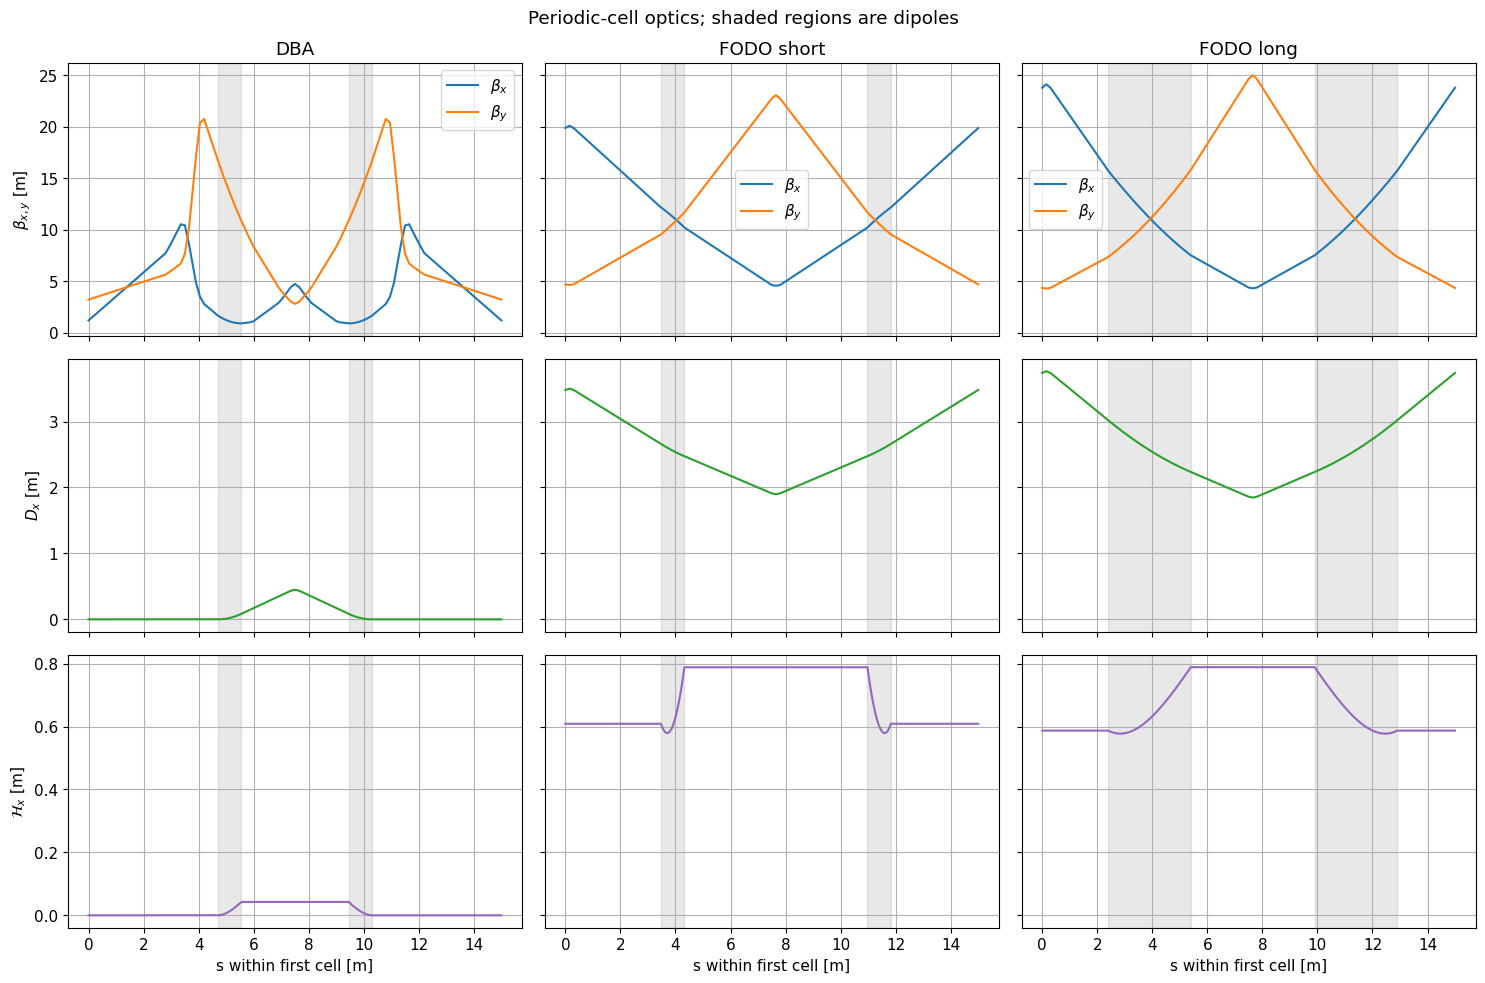

In [6]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10), sharex=True, sharey='row')
for col, (label, tw) in enumerate(twiss.items()):
    mask = tw.s <= cell_length + 1e-9
    s = tw.s[mask]
    axes[0, col].plot(s, tw.betx[mask], label=r'$\beta_x$')
    axes[0, col].plot(s, tw.bety[mask], label=r'$\beta_y$')
    axes[0, col].set_title(label)
    axes[0, col].legend()
    axes[1, col].plot(s, tw.dx[mask], color='tab:green')
    axes[2, col].plot(s, tw.rad_int_curly_hx[mask], color='tab:purple')
    axes[2, col].set_xlabel('s within first cell [m]')
    # Shading marks the physical dipoles, using the unsliced layout.
    table = models[label].get_table(attr=True)
    for ss, ll, typ in zip(table.s, table.length, table.element_type):
        if typ == 'Bend' and ss < cell_length - 1e-9:
            for ax in axes[:, col]:
                ax.axvspan(ss, ss + ll, color='gray', alpha=0.18)
axes[0, 0].set_ylabel(r'$\beta_{x,y}$ [m]')
axes[1, 0].set_ylabel(r'$D_x$ [m]')
axes[2, 0].set_ylabel(r'$\mathcal{H}_x$ [m]')
fig.suptitle('Periodic-cell optics; shaded regions are dipoles')
fig.tight_layout()
plt.show()

## Compare energy loss and emittance

We independently check the bend-geometry formula for $I_2$ and the emittance formula using $I_4$ and $I_5$. All emittances below are **geometric horizontal equilibrium emittances**, not normalized emittances. No coupling or vertical dispersion is introduced.

,DBA,FODO short,FODO long
Dipole length [m],0.850000,0.850000,3.000000
Bending radius [m],4.329014,4.329014,15.278875
Dipole filling fraction,0.113333,0.113333,0.400000
I2 [1/m],1.451412,1.451412,0.411234
I5 [1/m],0.005246,0.212603,0.017369
Jx,0.993584,0.408309,0.830726
U0 [keV],170.669668,170.669668,48.356406
Emittance [nm],15.429133,1521.476397,215.627053
RMS momentum spread,0.000699,0.000615,0.000358


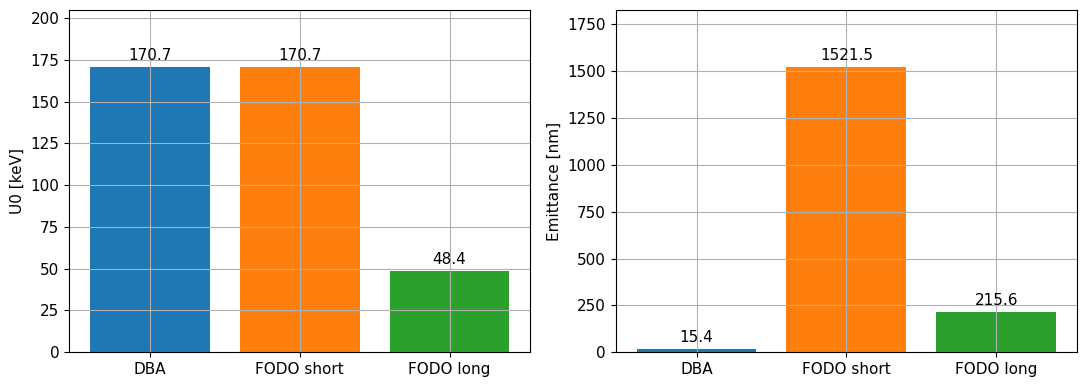

Long-bend FODO / DBA energy loss: 0.283
Long-bend FODO / DBA emittance: 13.98


In [7]:
Cq = 55 / (32 * np.sqrt(3)) * hbar / (m_e * c)
Cgamma = 8.846056192e-5  # m / GeV^3
rows = {}
for label, tw in twiss.items():
    rho = bend_lengths[label] / theta
    i2, i4, i5 = tw.rad_int_i2, tw.rad_int_i4x, tw.rad_int_i5x
    jx = 1 - i4 / i2
    gamma0 = float(fine_models[label].particle_ref.gamma0[0])
    u0 = Cgamma / (2 * np.pi) * (energy_eV / 1e9)**4 * i2 * 1e9
    emit = Cq * gamma0**2 * i5 / (jx * i2)
    np.testing.assert_allclose(i2, n_bends * theta**2 / bend_lengths[label], rtol=1e-5)
    np.testing.assert_allclose(u0, tw.rad_int_energy_loss, rtol=1e-4)
    np.testing.assert_allclose(emit, tw.rad_int_eq_gemitt_x, rtol=1e-5)
    assert jx > 0
    rows[label] = {'Dipole length [m]': bend_lengths[label],
                   'Bending radius [m]': rho,
                   'Dipole filling fraction': n_bends * bend_lengths[label] / circumference,
                   'I2 [1/m]': i2, 'I5 [1/m]': i5, 'Jx': jx,
                   'U0 [keV]': u0 / 1e3, 'Emittance [nm]': emit * 1e9,
                   'RMS momentum spread': tw.rad_int_sigma_delta}
results = pd.DataFrame(rows).T
display(results.T)
np.testing.assert_allclose(results.loc['FODO short', 'U0 [keV]'],
                           results.loc['DBA', 'U0 [keV]'], rtol=1e-5)
np.testing.assert_allclose(results.loc['FODO long', 'U0 [keV]'] / results.loc['DBA', 'U0 [keV]'],
                           short_bend / long_bend, rtol=1e-5)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, column in zip(axes, ['U0 [keV]', 'Emittance [nm]']):
    bars = ax.bar(results.index, results[column], color=['tab:blue', 'tab:orange', 'tab:green'])
    ax.bar_label(bars, fmt='%.1f', padding=3)
    ax.set_ylabel(column)
    ax.set_ylim(0, 1.2 * results[column].max())
fig.tight_layout()
plt.show()
print(f"Long-bend FODO / DBA energy loss: {results.loc['FODO long', 'U0 [keV]'] / results.loc['DBA', 'U0 [keV]']:.3f}")
print(f"Long-bend FODO / DBA emittance: {results.loc['FODO long', 'Emittance [nm]'] / results.loc['DBA', 'Emittance [nm]']:.2f}")

## Check integration resolution and 6D equilibrium

First double the number of bend slices while keeping physical magnet strengths fixed. Then enable mean radiation and RF to calculate the full-ring 6D equilibrium, including the energy sawtooth. Xsuite computes equilibrium quantum excitation in the radiation analysis; stochastic photon tracking is not needed.

For the comparison we use a common **0.30 MV RF voltage**, above the largest energy loss, with harmonic number 400. This differs from the 1.5 MV in notebook 00; RF voltage does not enter the preceding 4D radiation integrals. The FODO cavity sits at nonzero dispersion, and its 6D horizontal and longitudinal modes couple. At 1.5 MV the synchrotron tune approaches the fractional horizontal tune and the 6D emittance differs substantially from the uncoupled integral estimate. The lower voltage keeps this effect small for our chosen working point.

The 6D calculation also includes the radiative closed orbit. We report its emittance separately and check agreement with the integral approximation within 2%. This agreement is specific to the selected RF and tunes.

In [8]:
convergence_rows = []
for label, line in models.items():
    finer = sliced_copy(line, 64)
    if label == 'DBA':
        for knob in ['ksf', 'ksd']:
            finer.vars[knob] = fine_models[label].vars.val[knob]
    tw64 = finer.twiss4d(radiation_integrals=True)
    relative_change = tw64.rad_int_eq_gemitt_x / twiss[label].rad_int_eq_gemitt_x - 1
    convergence_rows.append({'Model': label,
                             '32 slices [nm]': 1e9 * twiss[label].rad_int_eq_gemitt_x,
                             '64 slices [nm]': 1e9 * tw64.rad_int_eq_gemitt_x,
                             'Change [%]': 100 * relative_change})
    assert abs(relative_change) < 0.005
convergence = pd.DataFrame(convergence_rows).set_index('Model')
display(convergence)

radiation_rows = []
for label, line in fine_models.items():
    line.configure_radiation(model='mean')
    rad = line.twiss(method='6d', radiation_analysis=True)
    assert rad.qs > 0
    assert np.all(rad.damping_constants_s > 0)
    np.testing.assert_allclose(rad.energy_loss, twiss[label].rad_int_energy_loss, rtol=0.01)
    np.testing.assert_allclose(rad.eq_gemitt_x, twiss[label].rad_int_eq_gemitt_x, rtol=0.02)
    radiation_rows.append({'Model': label, 'U0, 6D [keV]': rad.energy_loss / 1e3,
                           'Emittance, 6D [nm]': rad.eq_gemitt_x * 1e9,
                           'Horizontal damping time [ms]': 1e3 / rad.damping_constants_s[0],
                           'Synchrotron tune': rad.qs})
    line.configure_radiation(model=None)
radiation_results = pd.DataFrame(radiation_rows).set_index('Model')
display(radiation_results)
print('Comparison completed: geometry, tunes, radiation formulas, slicing and 6D checks passed.')

Slicing line:   0%|          | 0/465 [00:00<?, ?it/s]

Slicing line:   0%|          | 0/129 [00:00<?, ?it/s]

Slicing line:   0%|          | 0/129 [00:00<?, ?it/s]

,32 slices [nm],64 slices [nm],Change [%]
Model,,,
DBA,15.429133,15.424868,-0.027643
FODO short,1521.476397,1521.359711,-0.007669
FODO long,215.627053,215.616003,-0.005125


,"U0, 6D [keV]","Emittance, 6D [nm]",Horizontal damping time [ms],Synchrotron tune
Model,,,,
DBA,170.673842,15.429334,16.050827,0.002591
FODO short,170.673877,1541.313633,39.115065,0.024941
FODO long,48.357592,219.327891,67.784161,0.027466


Comparison completed: geometry, tunes, radiation formulas, slicing and 6D checks passed.


## Interpretation and exercises

Read the short-bend FODO and DBA columns first: their equal $I_2$ gives equal energy loss, while the optics-dependent $I_5/(J_xI_2)$ sets different emittances. Next compare the two FODO columns: longer bends lower energy loss, but also change dispersion and $\mathcal{H}_x$ even after rematching the same tunes. This is not a scan with frozen optics.

The long-bend FODO illustrates how lower energy loss can coexist with higher emittance than the DBA. It also uses fewer quadrupoles and sacrifices dispersion-free straights. This is a comparison of three specified teaching lattices, not a universal ranking of lattice families.

1. Change the long dipole length to 2 or 4 m and rerun. Verify the inverse-length scaling of energy loss. Does emittance follow a similarly simple law?
2. Change both FODO tunes near the nominal 90° cell working point, keeping away from exact integer ring tunes. Plot emittance versus phase advance, and examine $\mathcal{H}_x$ in the bends.
3. Compare the damping times. Explain why lower energy loss generally means slower damping at the same energy, and check the role of $J_x$.
4. Restore 1.5 MV RF and compare the 6D equilibrium with the integral estimate (the 2% agreement check may fail). Inspect the horizontal and synchrotron tunes and the dispersion at the cavity.
5. Consider which geometric and optical constraints would be needed to compare rings with the same insertion-device straight sections.

References: [Xsuite radiation-integral and equilibrium API](https://xsuite.readthedocs.io/en/latest/apireference.html), [Xsuite physics guide](https://xsuite.readthedocs.io/en/latest/physicsguide.html), and notebook 00 for the DBA construction and BESSY II source parameters.